In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [15]:
df = pd.read_csv('C:/Users/Genesis/M30 Online Retail.csv', encoding='latin-1')
df.head()

,INVOICE_NO,STOCK_CODE,DESCRIPTION,QUANTITY,INVOICE_DATE,UNIT_PRICE,CUSTOMER_ID,REGION
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2019 08:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2019 08:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2019 08:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2019 08:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2019 08:26,3.39,17850.0,United Kingdom


In [16]:
df = df.dropna(subset=['CUSTOMER_ID'])
df['CUSTOMER_ID'] = df['CUSTOMER_ID'].astype(int)

In [20]:
df['INVOICE_DATE'] = pd.to_datetime(df['INVOICE_DATE'], dayfirst=True)

In [21]:
df['TOTAL_PRICE'] = df['QUANTITY'] * df['UNIT_PRICE']

In [22]:
import datetime as dt

fecha_actual = df['INVOICE_DATE'].max() + dt.timedelta(days=1)
print(fecha_actual)

2020-12-10 12:50:00


In [23]:
rfm = df.groupby('CUSTOMER_ID').agg({
    'INVOICE_DATE': lambda x: (fecha_actual - x.max()).days,
    'INVOICE_NO': 'nunique',
    'TOTAL_PRICE': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm.head()

,Recency,Frequency,Monetary
CUSTOMER_ID,,,
12346,327,2,0.00
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,311,1,334.40


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

In [25]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3, random_state=42)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

rfm.head()

,Recency,Frequency,Monetary,Cluster
CUSTOMER_ID,,,,
12346,327,2,0.00,1
12347,2,7,4310.00,0
12348,75,4,1797.24,0
12349,19,1,1757.55,0
12350,311,1,334.40,1


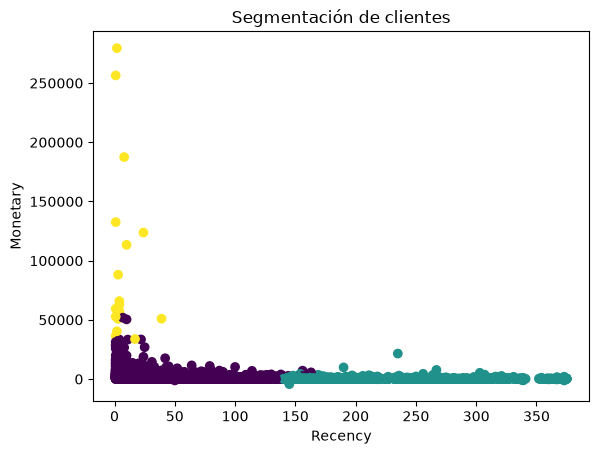

In [26]:
import matplotlib.pyplot as plt

plt.scatter(rfm['Recency'], rfm['Monetary'], c=rfm['Cluster'])
plt.xlabel('Recency')
plt.ylabel('Monetary')
plt.title('Segmentación de clientes')
plt.show()

In [27]:
rfm.groupby('Cluster').mean()

,Recency,Frequency,Monetary
Cluster,,,
0,40.060130,5.596361,1822.337475
1,246.570524,1.847197,459.313437
2,6.086957,86.869565,81835.857391


## Análisis de resultados del modelo RFM
Segmentación de clientes

A partir del análisis RFM (Recency, Frequency y Monetary), se logró clasificar a los clientes en distintos grupos de acuerdo con su comportamiento de compra.

Los clientes con alta frecuencia de compra y alto gasto representan los clientes más valiosos para la empresa.
Los clientes con baja frecuencia y bajo gasto corresponden a segmentos con menor impacto comercial.
Los clientes con baja recencia indican que no han realizado compras recientemente, lo cual puede representar un riesgo de pérdida.
Insights principales
Se identificó un grupo de clientes recurrentes con alto valor monetario, los cuales deben ser prioridad para estrategias de fidelización.
Existen clientes con compras esporádicas que pueden ser incentivados mediante promociones o campañas específicas.
La recencia permite detectar clientes inactivos que pueden ser recuperados con estrategias de reactivación.
Implicaciones estratégicas
Implementar campañas de retención dirigidas a los clientes más valiosos.
Diseñar promociones para aumentar la frecuencia de compra en clientes ocasionales.
Desarrollar estrategias de reactivación para clientes que no han comprado recientemente.

Conclusión

El modelo RFM permite segmentar eficazmente a los clientes con base en su comportamiento de compra, facilitando la toma de decisiones estratégicas. Este análisis ayuda a identificar oportunidades para mejorar la retención, aumentar el valor del cliente y optimizar las estrategias comerciales de la empresa.

## Análisis detallado de los segmentos RFM
Descripción de los subgrupos

A partir del análisis RFM, los clientes fueron agrupados en diferentes segmentos con características específicas:

Segmento 1: Clientes Premium (Alto RFM)
Estos clientes presentan valores altos en frecuencia y gasto monetario, además de haber realizado compras recientemente. Representan el grupo más valioso para la empresa y muestran una alta lealtad.
Segmento 2: Clientes Frecuentes (Frecuencia alta, gasto medio)
Este grupo compra con regularidad, pero su gasto no es tan elevado. Son clientes importantes que pueden ser incentivados para aumentar su valor monetario.
Segmento 3: Clientes Ocasionales (Frecuencia baja, gasto bajo)
Estos clientes realizan compras esporádicas y representan un segmento con bajo impacto económico. Requieren estrategias para aumentar su frecuencia de compra.
Segmento 4: Clientes Inactivos (Alta recencia)
Son clientes que no han realizado compras recientemente. Existe riesgo de pérdida, por lo que se recomienda implementar estrategias de reactivación.
Interpretación de los resultados

El análisis permite observar que:

Existe una clara diferenciación entre clientes de alto valor y clientes de bajo valor.
Los clientes premium concentran una gran proporción de los ingresos.
Los clientes inactivos representan una oportunidad de recuperación si se aplican campañas adecuadas.
La frecuencia y el gasto son factores clave para determinar el valor del cliente.
Conclusiones
La segmentación RFM es efectiva para identificar distintos perfiles de clientes.
Permite enfocar estrategias comerciales específicas para cada segmento.
Facilita la toma de decisiones en marketing, retención y fidelización.